# Session 2 — Logs in regressions: elasticities, interpretation, and zeros

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.1 (Regression Review II, applied part). Everything
here is simulated with a known truth, so every interpretation rule can be
checked against the number that generated the data. Four parts:

1. Why logs: linear vs. proportional effects, and the log–log model as an
   elasticity.
2. Reading log coefficients: exact vs. approximate, and the error of the
   approximation.
3. The log base 1.1 trick (Huntington-Klein 2023): coefficients that read as
   "the effect of a 10 % increase".
4. Zeros: $\log(1+Y)$ and $\operatorname{arcsinh}(Y)$ are not elasticities
   (Chen and Roth 2024; Mullahy and Norton 2024) — and what to do instead.

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`. Run top to
bottom; in the lecture we step through one cell at a time.


In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261019)
pd.set_option("display.precision", 4)

# Okabe-Ito palette, minimal theme (repo convention)
BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.family": "sans-serif",
})

def ols(formula, data, **kw):
    '''OLS with HC1 robust SEs, returns the fitted statsmodels result.'''
    return smf.ols(formula, data=data).fit(cov_type="HC1", **kw)

def coef_table(*fits, names=None):
    '''Side-by-side coefficients (SE) for a few fitted models.'''
    names = names or [f"({i+1})" for i in range(len(fits))]
    rows = {}
    for f, nm in zip(fits, names):
        for p in f.params.index:
            rows.setdefault(p, {})[nm] = f"{f.params[p]:.4f} ({f.bse[p]:.4f})"
    return pd.DataFrame(rows).T.fillna("")


## 1. Linear vs. proportional: where logs come from

A linear model says that adding one unit to $x$ adds a fixed amount
$\beta_1$ to $y$, whatever the level of $x$. Many economic relationships are
instead *proportional*: a 1 % change in $x$ changes $y$ by a fixed
percentage. The multiplicative model

$$y = \alpha\, x^{\beta_1} e^{u}$$

becomes linear in logs,

$$\ln y = \ln\alpha + \beta_1 \ln x + u,$$

and $\beta_1$ is the elasticity
$\varepsilon_{y,x} = \dfrac{d y / y}{d x / x} = \dfrac{d \ln y}{d \ln x}$.

We simulate a demand-type relationship with true elasticity $-1.5$ and
estimate it in levels and in logs.


In [2]:
n = 2000
price = np.exp(rng.normal(np.log(10), 0.5, n))            # log-normal prices around 10
u = rng.normal(0, 0.3, n)
alpha, beta_true = 500.0, -1.5
quantity = alpha * price**beta_true * np.exp(u)           # true DGP: constant elasticity

df = pd.DataFrame({"price": price, "quantity": quantity})
df["ln_price"], df["ln_quantity"] = np.log(df.price), np.log(df.quantity)

fit_lin = ols("quantity ~ price", df)
fit_log = ols("ln_quantity ~ ln_price", df)
coef_table(fit_lin, fit_log, names=["levels", "log-log"])


,levels,log-log
Intercept,47.0565 (1.4632),6.2063 (0.0337)
price,-2.2298 (0.1112),
ln_price,,-1.4967 (0.0144)


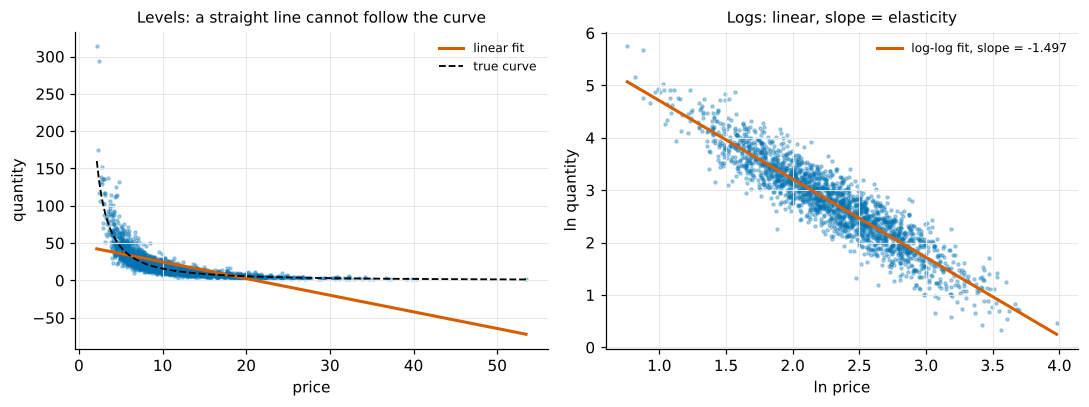

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
grid = np.linspace(df.price.min(), df.price.max(), 200)

ax = axes[0]
ax.scatter(df.price, df.quantity, s=4, alpha=0.3, color=BLUE)
ax.plot(grid, fit_lin.params["Intercept"] + fit_lin.params["price"] * grid, color=VERMILLION, lw=2, label="linear fit")
ax.plot(grid, alpha * grid**beta_true, color="black", lw=1.2, ls="--", label="true curve")
ax.set_xlabel("price"); ax.set_ylabel("quantity"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Levels: a straight line cannot follow the curve", fontsize=10)

ax = axes[1]
ax.scatter(df.ln_price, df.ln_quantity, s=4, alpha=0.3, color=BLUE)
lg = np.linspace(df.ln_price.min(), df.ln_price.max(), 50)
ax.plot(lg, fit_log.params["Intercept"] + fit_log.params["ln_price"] * lg, color=VERMILLION, lw=2,
        label=f"log-log fit, slope = {fit_log.params['ln_price']:.3f}")
ax.set_xlabel("ln price"); ax.set_ylabel("ln quantity"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Logs: linear, slope = elasticity", fontsize=10)
plt.tight_layout(); plt.show()


The linear fit is not "wrong" — it is the best linear predictor of quantity
given price — but its slope is a dollar-per-unit number that changes with
the price level, and it misses the curvature entirely. The log–log slope
recovers the elasticity ($-1.5$) directly.

**Misconception to drop now:** logs do *not* make data normal, and OLS does
not assume normal data anyway (only, for exact finite-sample inference,
normal *errors*). We take logs because the economics is proportional and
because logs tame right-skewed variables, not to fix a histogram.


## 2. Reading log coefficients: exact vs. approximate

Three log specifications and their exact interpretation:

| Model | Coefficient $\beta$ means | Exact | Approximation |
|---|---|---|---|
| $y = \beta_0 + \beta_1 \ln x$ | a $p$ % increase in $x$ changes $y$ by | $\beta_1 \ln(1+p)$ units | $\beta_1 \cdot p$ units |
| $\ln y = \beta_0 + \beta_1 x$ | a one-unit increase in $x$ changes $y$ by | $(e^{\beta_1} - 1)\cdot 100$ % | $\beta_1 \cdot 100$ % |
| $\ln y = \beta_0 + \beta_1 \ln x$ | a $p$ % increase in $x$ changes $y$ by | $\big((1+p)^{\beta_1} - 1\big)\cdot 100$ % | $\beta_1 \cdot p \cdot 100$ % |

The approximation rests on $\ln(1+p) \approx p$ for small $p$. Below is how
fast it deteriorates.

**What "exact" refers to.** A regression with $\ln y$ on the left models
$\mathbb{E}[\ln y \mid x]$, i.e. the log of the conditional *geometric* mean.
$e^{\beta_1}-1$ is therefore the exact proportional change in the geometric
mean of $y$ (equivalently: the exact multiplier for an individual whose error
term is held fixed). It equals the proportional change in the *arithmetic*
mean $\mathbb{E}[y \mid x]$ only if the error distribution does not change
with $x$ (homoskedastic in the log model) — otherwise a retransformation
(smearing) factor is needed. In the simulation below that condition holds,
so the two coincide.


In [4]:
p = np.array([0.01, 0.05, 0.10, 0.20, 0.30, 0.50, 1.00])
tab = pd.DataFrame({
    "% increase": (p * 100).astype(int),
    "approx  ln(1+p) ≈ p": p,
    "exact   ln(1+p)": np.log1p(p),
})
tab["relative error (%)"] = 100 * (tab["approx  ln(1+p) ≈ p"] / tab["exact   ln(1+p)"] - 1)
tab


,% increase,approx ln(1+p) ≈ p,exact ln(1+p),relative error (%)
0,1,0.01,0.0100,0.4992
1,5,0.05,0.0488,2.4797
2,10,0.10,0.0953,4.9206
3,20,0.20,0.1823,9.6963
4,30,0.30,0.2624,14.3448
5,50,0.50,0.4055,23.3152
6,100,1.00,0.6931,44.2695


For a log *outcome* the same issue appears on the other side: a coefficient
of 0.25 on a dummy is not a 25 % effect but $e^{0.25}-1 = 28.4$ %; a
coefficient of $-0.5$ is $-39$ %, not $-50$ %. Let us see this in a simulated
log-level regression with a known multiplicative treatment effect.


In [5]:
n = 5000
d = rng.binomial(1, 0.5, n)                                 # treatment dummy
x = rng.normal(0, 1, n)
true_mult = 1.40                                            # treatment multiplies y by 1.40 (+40 %)
y = np.exp(1.0 + 0.3 * x + np.log(true_mult) * d + rng.normal(0, 0.4, n))
dl = pd.DataFrame({"y": y, "ln_y": np.log(y), "d": d, "x": x})

fit = ols("ln_y ~ d + x", dl)
b = fit.params["d"]
print(f"coefficient on d          : {b:.4f}")
print(f"approximate effect  b*100 : {100*b:.1f} %")
print(f"exact effect  (exp(b)-1)  : {100*(np.exp(b)-1):.1f} %      (truth: +{100*(true_mult-1):.0f} %)")


coefficient on d          : 0.3317
approximate effect  b*100 : 33.2 %
exact effect  (exp(b)-1)  : 39.3 %      (truth: +40 %)


## 3. The log base 1.1 trick (Huntington-Klein 2023)

Nothing forces the natural logarithm. For any base $b$,
$\log_b(x) = \ln(x)/\ln(b)$, so changing the base only rescales the
coefficient — but it changes what "one unit" means. With base 1.1,
one unit of $\log_{1.1}(x)$ is exactly a 10 % increase in $x$, because
$\log_{1.1}(1.1\,x) = \log_{1.1}(x) + 1$. Hence:

1. $y = \beta_0 + \beta_1 \log_{1.1}(x)$: $\beta_1$ is the effect of a
   **10 % increase** in $x$ on $y$, in units of $y$ — exact, no
   approximation.
2. $\log_{1.1}(y) = \beta_0 + \beta_1 x$: a one-unit increase in $x$
   multiplies $y$ by $1.1^{\beta_1}$.
3. $\log_{1.1}(y) = \beta_0 + \beta_1 \log_{1.1}(x)$: a 10 % increase in
   $x$ multiplies $y$ by $1.1^{\beta_1}$.

We reproduce the lecture example with simulated data where the truth is
known.


In [6]:
def log11(v):
    return np.log(v) / np.log(1.1)

n = 4000
x_pos = np.exp(rng.normal(2, 0.6, n))                      # positive regressor
x_lin = rng.normal(3, 1, n)                                # regressor in levels
# (1) y on log_1.1(x): a 10 % increase in x raises y by 0.148 units
y1 = 2 + 0.148 * log11(x_pos) + rng.normal(0, 0.5, n)
# (2) log_1.1(y) on x: a one-unit increase in x multiplies y by 1.25
y2 = np.exp(0.5 + np.log(1.25) * x_lin + rng.normal(0, 0.3, n))
# (3) log-log: a 10 % increase in x multiplies y by 1.0316
y3 = np.exp(0.2 + np.log(1.0316) * log11(x_pos) + rng.normal(0, 0.3, n))

dd = pd.DataFrame({"x_pos": x_pos, "x_lin": x_lin, "y1": y1, "y2": y2, "y3": y3})
dd["l11_x"], dd["l11_y2"], dd["l11_y3"] = log11(dd.x_pos), log11(dd.y2), log11(dd.y3)

f1 = ols("y1 ~ l11_x", dd); f2 = ols("l11_y2 ~ x_lin", dd); f3 = ols("l11_y3 ~ l11_x", dd)
coef_table(f1, f2, f3, names=["(1) y on log1.1(x)", "(2) log1.1(y) on x", "(3) log1.1(y) on log1.1(x)"])


,(1) y on log1.1(x),(2) log1.1(y) on x,(3) log1.1(y) on log1.1(x)
Intercept,2.0306 (0.0261),5.4447 (0.1645),2.0229 (0.1694)
l11_x,0.1470 (0.0012),,0.3310 (0.0078)
x_lin,,2.3077 (0.0525),


In [7]:
b1, b2, b3 = f1.params["l11_x"], f2.params["x_lin"], f3.params["l11_x"]
print(f"(1) a 10% increase in x raises y by {b1:.3f} units              (truth 0.148)")
print(f"(2) one more unit of x multiplies y by 1.1^{b2:.3f} = {1.1**b2:.4f}  -> +{100*(1.1**b2-1):.2f} %  (truth +25 %)")
print(f"    eyeballing '10% of {b2:.3f}' = {10*b2:.2f} %  is the approximation; the exact number is above")
print(f"(3) a 10% increase in x multiplies y by 1.1^{b3:.3f} = {1.1**b3:.4f}  -> +{100*(1.1**b3-1):.2f} %  (truth +3.16 %)")

# the natural-log version of (2) gives the same exact effect after conversion
f2_ln = ols("np.log(y2) ~ x_lin", dd)
print(f"\n(2) with ln instead of log1.1: coefficient {f2_ln.params['x_lin']:.4f}, exp(b)-1 = +{100*(np.exp(f2_ln.params['x_lin'])-1):.2f} %")


(1) a 10% increase in x raises y by 0.147 units              (truth 0.148)
(2) one more unit of x multiplies y by 1.1^2.308 = 1.2460  -> +24.60 %  (truth +25 %)
    eyeballing '10% of 2.308' = 23.08 %  is the approximation; the exact number is above
(3) a 10% increase in x multiplies y by 1.1^0.331 = 1.0320  -> +3.20 %  (truth +3.16 %)

(2) with ln instead of log1.1: coefficient 0.2199, exp(b)-1 = +24.60 %


Same information, different base. The trick does its real work when the
*regressor* is logged: one unit of $\log_{1.1}(x)$ is a 10 % increase in $x$,
full stop, so the coefficient reads directly. When the *outcome* is logged you
still have to exponentiate ($1.1^{\beta}$ rather than $e^{\beta}$); the base
only changes which number you raise to the power. The trick is most useful when a regression has several logged
regressors and you want every coefficient to read as "a 10 % increase in …".


## 4. Zeros: $\log(1+Y)$ and $\operatorname{arcsinh}(Y)$ are not elasticities

Spending, sales, patents, hours worked: nonnegative, right-skewed, with a
mass at zero. $\ln Y$ is undefined at zero, and the usual fixes are
$\ln(1+Y)$ or $\operatorname{arcsinh}(Y) = \ln(Y + \sqrt{Y^2+1})$, both
$\approx Y$ near zero; for large $Y$, $\ln(1+Y) \approx \ln Y$ while
$\operatorname{arcsinh}(Y) \approx \ln(2Y) = \ln Y + \ln 2$ — the constant is
harmless for slopes when every $Y$ is positive, but it is added only to the
positive observations, so with zeros it changes the extensive-margin
loading just as the units do.

The problem (Chen and Roth 2024; Mullahy and Norton 2024): with zeros these
transformations are **not scale-invariant**. Measuring $Y$ in cents instead of
dollars changes the estimated "percentage effect" — arbitrarily — because
the transform treats "is $Y$ zero?" and "how large is $Y$?" differently, and
the units decide how much weight the extensive margin gets. An elasticity
cannot depend on the unit of measurement.

We simulate a treatment that (a) moves some units from $Y=0$ to $Y>0$ and
(b) raises $Y$ among those already positive, and estimate the "effect" with
the usual transformations under different units.


In [8]:
n = 50000
d = rng.binomial(1, 0.5, n)
# extensive margin: treatment raises the share with Y>0 from 60 % to 70 %
active = rng.uniform(size=n) < (0.60 + 0.10 * d)
# intensive margin: among active units, treatment multiplies Y by 1.20
y_pos = np.exp(rng.normal(3.0, 0.8, n) + np.log(1.20) * d)
Y = np.where(active, y_pos, 0.0)                             # in "dollars"
dz = pd.DataFrame({"Y": Y, "d": d})

print(f"share Y>0 : control {np.mean(Y[d==0]>0):.3f}   treated {np.mean(Y[d==1]>0):.3f}")
print(f"E[Y]      : control {Y[d==0].mean():.2f}   treated {Y[d==1].mean():.2f}   -> true effect on E[Y]: "
      f"+{100*(Y[d==1].mean()/Y[d==0].mean()-1):.1f} %")


share Y>0 : control 0.596   treated 0.696
E[Y]      : control 16.54   treated 23.18   -> true effect on E[Y]: +40.2 %


In [9]:
rows = []
for scale, unit in [(0.01, "hundreds of $"), (1, "$"), (100, "cents")]:
    Ys = Y * scale
    for name, g in [("log(1+Y)", np.log1p), ("arcsinh(Y)", np.arcsinh)]:
        tmp = pd.DataFrame({"t": g(Ys), "d": d})            # fresh frame per case: no shared state left behind
        b = ols("t ~ d", tmp).params["d"]
        rows.append({"transform": name, "units": unit, "coefficient on d": b, "naive '% effect'": 100 * b})
pd.DataFrame(rows).pivot(index="transform", columns="units", values="coefficient on d")[["hundreds of $", "$", "cents"]]


units,hundreds of $,$,cents
transform,,,
arcsinh(Y),0.0600,0.4937,0.9554
log(1+Y),0.0493,0.4242,0.8859


The same data, the same treatment, and the coefficient on $d$ moves from
0.05 to 0.89 — eighteen-fold — just because we changed the unit. (Multiplying
it by 100 and calling it a percentage effect, as is common, does not make it
one; no reading of this number is unit-free.) The reason is visible
in the transform: $\ln(1+Y)$ for an active unit is $\approx \ln Y + \ln(\text{scale})$,
while for a zero it stays $0$, so the gap between zeros and positives — the
extensive margin — grows without bound as the scale grows. This is the
pattern Chen and Roth (2024) document for published papers: the
*estimated coefficient* in a $\ln(1+Y)$ or arcsinh regression — the quantity
reported as a treatment effect — changes by a large multiple when the
outcome is rescaled, because the estimand of the transformed regression
itself depends on the units. (A fixed causal effect does not change; what the
regression estimates does.)

What does not depend on units:


In [10]:
rows = []
for scale, unit in [(0.01, "hundreds of $"), (1, "$"), (100, "cents")]:
    dz["Ys"] = Y * scale
    dz["pos"] = (dz.Ys > 0).astype(float)
    # (a) extensive margin: linear probability model on 1{Y>0}
    ext = ols("pos ~ d", dz).params["d"]
    # (b) intensive margin: log Y among positives
    pos_only = dz[dz.pos == 1].assign(ln_Ys=lambda f: np.log(f.Ys))
    inten = ols("ln_Ys ~ d", pos_only).params["d"]
    # (c) effect on E[Y] in percent: levels OLS relative to control mean
    lev = ols("Ys ~ d", dz).params["d"] / dz.Ys[dz.d == 0].mean()
    # (d) Poisson pseudo-ML on untransformed Y: coefficient = log of proportional effect on E[Y]
    pois = sm.GLM(dz.Ys, sm.add_constant(dz.d), family=sm.families.Poisson()).fit().params["d"]
    rows.append({"units": unit, "P(Y>0): LPM": ext, "ln Y | Y>0": inten,
                 "E[Y] % (levels OLS)": 100 * lev, "E[Y] % (Poisson, exp(b)-1)": 100 * (np.exp(pois) - 1)})
pd.DataFrame(rows).set_index("units")


,P(Y>0): LPM,ln Y | Y>0,E[Y] % (levels OLS),"E[Y] % (Poisson, exp(b)-1)"
units,,,,
hundreds of $,0.1002,0.1772,40.1559,40.1559
$,0.1002,0.1772,40.1559,40.1559
cents,0.1002,0.1772,40.1559,40.1559


Every column is stable across units, and each answers a well-posed question:

- **Two-part / hurdle view:** the treatment raises the probability of a
  positive outcome by about 0.10 (truth 0.10), and among observed positives
  $\ln Y$ is higher by about 0.18 ($e^{b}-1 \approx 20$ %; truth 20 %).
  Caution on the second number: conditioning on $Y>0$ conditions on a
  post-treatment outcome. In general the treatment changes *who* is positive,
  so the contrast among positives mixes the intensive-margin effect with
  selection and is not point-identified as a causal effect (Chen and Roth
  2024 discuss bounds). It is clean here only because the simulation draws
  activity and amount independently. Report both margins, but label the
  second one descriptively unless you can defend the selection assumption
  (Mullahy and Norton 2024).
- **Proportional effect on the mean:** with only a treatment dummy, both
  estimators below are the ratio of group means $\mathbb{E}[Y \mid d{=}1] / \mathbb{E}[Y \mid d{=}0]$
  in disguise — levels OLS divided by the control mean, and Poisson
  pseudo-maximum likelihood on the *untransformed* $Y$. With covariates they
  part ways: Poisson PML estimates $\ln \mathbb{E}[Y\mid X] = X\beta$ and is
  consistent whenever that multiplicative conditional-mean specification is
  right, zeros included; a levels-OLS coefficient divided by an overall
  control mean is no longer a proportional effect at all (exercise 4). Chen
  and Roth (2024) recommend Poisson for exactly this reason. Nothing about
  counts or a Poisson distribution is assumed — it is a quasi-likelihood for
  a mean model.

Rules of thumb for your own work:

1. If $Y$ is strictly positive, $\ln Y$ is unit-invariant and the conversions
   of Part 2 apply (with the geometric-mean caveat stated there). It settles
   the units question only — functional form and identification are
   separate questions.
2. If $Y$ has zeros, do not reach for $\ln(1+Y)$ or arcsinh and call it an
   elasticity. Decide what you want — margins, or the effect on the mean —
   and use the matching estimator above.
3. Whatever you do, check that your estimate does not change when you change
   the units of $Y$. If it does, it is not measuring what you think.


## 5. Exercises

1. **Approximation error in practice.** In the log-level regression of
   Part 2, change `true_mult` to 1.05, 1.5, 2.0 and 0.5. For each, compare
   $100\,b$ with $100\,(e^{b}-1)$. At what size of effect would you stop
   using the approximation?
2. **Base 1.1 by hand.** Take `f2_ln` (natural log of `y2` on `x_lin`) and
   convert its coefficient to the base-1.1 coefficient without re-estimating.
   Verify against `f2`.
3. **Where does the scale dependence come from?** In Part 4, set the
   extensive-margin effect to zero (`0.60 + 0.00 * d`) and rerun the
   rescaling table; then restore it and set the intensive-margin effect to
   zero (`np.log(1.00)`). Re-run the whole of Part 4 from its first cell each
   time (it rebuilds `d`, `active`, `Y` and reseeds its own generator), and use
   $n = 500{,}000$ so that random imbalance in the
   share of zeros does not muddy the picture, and compare the *spread* of the
   coefficient across units in the two cases. Which margin drives the
   instability of $\ln(1+Y)$, and why does a small finite-sample imbalance in
   the share of zeros still produce some movement?
4. **Poisson vs. levels.** Add a covariate $x$ that affects both the
   probability of $Y>0$ and the level of $Y$. Fix the target first: the
   average treatment contrast on the mean, $\mathbb{E}[Y(1)] - \mathbb{E}[Y(0)]$
   (or its ratio), computed from each model by predicting every unit once
   with $d=1$ and once with $d=0$ and averaging ("standardization"). Compare
   the levels-OLS and Poisson versions of that contrast with and without
   $x$. Then compare the raw coefficients — note that they are different
   objects (a linear-projection coefficient vs. a conditional multiplicative
   parameter), so a direct comparison of coefficients is not meaningful
   once covariates enter.

## References

- Huntington-Klein (2025), *The Effect*, 2nd ed., ch. 13.2.3 (Variable
  Transformations) — [theeffectbook.net](https://theeffectbook.net/ch-StatisticalAdjustment.html).
- Huntington-Klein, N. (2023), "My Unnatural War Against the Natural
  Logarithm," blog post on the base-1.1 trick —
  [nickchk.substack.com](https://nickchk.substack.com) (search the title;
  accessed October 2026).
- Chen, J. and J. Roth (2024), "Logs with Zeros? Some Problems and
  Solutions," *Quarterly Journal of Economics* 139(2), 891–936.
- Mullahy, J. and E. C. Norton (2024), "Why Transform Y? The Pitfalls of
  Transformed Regressions with a Mass at Zero," *Oxford Bulletin of Economics
  and Statistics* 86(2), 417–447.
- Bellemare, M. F. and C. J. Wichman (2020), "Elasticities and the Inverse
  Hyperbolic Sine Transformation," *Oxford Bulletin of Economics and
  Statistics* 82(1), 50–61.
